## Phase 4: Road segmentation
* Feature Extraction(OPenCV) -  color (grey/asphalt) + texture (smooth, uniform) + and shape (elongated, connected)
* Classification(ML) - (SVM/Random Forest/Shallow CNN)
* Post-Processing

In [61]:
# Basic Imports
import os
from datasets import load_dataset
import numpy as np
import math
import matplotlib.pyplot as plt
# Image operations
import cv2
# Random Forest
import skimage
from sklearn.ensemble import RandomForestClassifier

from skimage.feature import local_binary_pattern
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.metrics import classification_report

### Data Loading

In [62]:
# Load Datasets
def load_images2(class_folder, img_size=(512, 512), limit=100):
    count = 0
    X = []

    for file in os.listdir(class_folder):
        if count >= limit:
            break
        img_path = os.path.join(class_folder, file)

        # Read image (BGR)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files

        img = cv2.resize(img, img_size) # Resizing led to worse quality images with fewer keypoints

        X.append(img)
        count += 1

    return np.array(X)

In [63]:
train_folder = "Datasets/road/train"
test_folder = "Datasets/road/test"

train_img = []
train_label = []

image_files = sorted([f for f in os.listdir(train_folder) if f.endswith('_sat.jpg')])
mask_files = sorted([f for f in os.listdir(train_folder) if f.endswith('_mask.png')])

LIMIT = 200  # adjust based on your RAM
IMG_SIZE = (512, 512)

for img_file, mask_file in zip(image_files[:LIMIT], mask_files[:LIMIT]):
    img = cv2.imread(os.path.join(train_folder, img_file))
    mask = cv2.imread(os.path.join(train_folder, mask_file), cv2.IMREAD_GRAYSCALE)
    
    if img is None or mask is None:
        continue
    
    img = cv2.resize(img, IMG_SIZE)
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    binary_mask = (mask > 127).astype(np.uint8)

    train_img.append(img)
    train_label.append(binary_mask)


In [64]:
X_train = np.array(train_img)
Y_train = np.array(train_label)
X_test = load_images2("Datasets/road/test")

print("X train shape: ",X_train.shape)
print("Y Train shape: ",Y_train.shape)
print("X Test shape: ",X_test.shape)

X train shape:  (200, 512, 512, 3)
Y Train shape:  (200, 512, 512)
X Test shape:  (100, 512, 512, 3)


### Feature Extraction
for each image:     
- pad image   
- find road/nonroad pixel locations   
- sample locations    
- for each sampled location:      
    * extract patch from padded image 
    * compute HSV stats   
    * append to features list 
    * append label (1 for road, 0 for nonroad)    

In [65]:
def compute_lbp(patch_gray, radius=2, n_points=16):
    lpb = local_binary_pattern(patch_gray, n_points, radius, method='uniform')
    hist, _ = np.histogram(lpb, bins=n_points+2, range=(0, n_points+2))
    return hist.astype(float)/(hist.sum() + 1e-6)

In [66]:
def compute_sobel(patch_gray):
    sobelx = cv2.Sobel(patch_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(patch_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.sqrt(sobelx**2 + sobely**2)
    return [np.mean(magnitude), np.std(magnitude)]

In [ ]:
def feature_extraction(patch_size=15):
    
    # Padding images to help sample border patches
    patch_sizes = [15, 31]
    pad = max(patch_sizes) // 2
    
    features = []
    labels = []

    for i in range (LIMIT):

        img_padded = cv2.copyMakeBorder(X_train[i], pad, pad, pad, pad, cv2.BORDER_REFLECT)

        # Sampling road and non-road patches
        road_pixels = np.argwhere(Y_train[i] == 1)
        nonroad_pixels = np.argwhere(Y_train[i] == 0)

        n_samples = min(len(road_pixels), 500)

        road_sample = road_pixels[np.random.choice(len(road_pixels), n_samples, replace=False)]
        nonroad_sample = nonroad_pixels[np.random.choice(len(nonroad_pixels), n_samples, replace=False)]

        all_samples = np.vstack([
            np.column_stack((road_sample, np.ones(len(road_sample)))),
            np.column_stack((nonroad_sample, np.zeros(len(nonroad_sample))))
        ])

        h, w = Y_train[i].shape

        for sample in all_samples:
            row, col = int(sample[0]), int(sample[1])
            stats = []

            for ps in patch_sizes:
                pad_ps = ps // 2
                patch = img_padded[
                    row + pad - pad_ps : row + pad + pad_ps + 1,
                    col + pad - pad_ps : col + pad + pad_ps + 1
                ]

                # Safety Check
                if patch.size == 0:
                    continue

                if patch.shape[0] != ps or patch.shape[1] != ps:
                    print("BAD PATCH:", patch.shape)
                
                hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
                
                for j in range(3):
                    channel = hsv[:, :, j]
                    stats.append(np.mean(channel))
                    stats.append(np.std(channel))
                
                patch_gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
                b, g, r = cv2.split(patch)
                
                stats.extend(compute_lbp(patch_gray))
                stats.extend(compute_sobel(patch_gray))

                stats.append(np.mean(r / (g + 1e-6)))
                stats.append(np.mean(g / (b + 1e-6)))

            stats.append(row / h)
            stats.append(col / w)

            features.append(stats)
            labels.append(sample[2]) 
    return np.array(features), np.array(labels)

In [68]:
features, labels = feature_extraction()
indices = np.random.permutation(len(features))
X_shuffled = features[indices]
Y_shuffled = labels[indices]

print("Features:\n",X_shuffled[0])
print("Labels:\n",Y_shuffled[:5])

Features:
 [2.82355556e+01 3.71932823e+00 5.67644444e+01 5.31100139e+00
 1.00595556e+02 7.50116896e+00 1.24444444e-01 8.88888885e-02
 6.66666664e-02 3.55555554e-02 1.77777777e-02 2.66666665e-02
 1.77777777e-02 1.77777777e-02 2.22222221e-02 2.66666665e-02
 1.33333333e-02 4.44444442e-02 1.77777777e-02 4.44444442e-03
 1.33333333e-02 4.88888887e-02 3.55555554e-02 3.77777776e-01
 3.29073163e+01 2.70414842e+01 1.01646426e+00 1.25976736e+00
 3.00915713e+01 4.57063214e+00 5.57419355e+01 4.73919166e+00
 1.00813736e+02 6.40610228e+00 9.26118625e-02 6.65972944e-02
 4.26638917e-02 2.91363163e-02 1.24869927e-02 2.18522372e-02
 1.56087409e-02 1.87304891e-02 2.08116545e-02 3.12174818e-02
 1.45681582e-02 3.12174818e-02 1.56087409e-02 1.97710718e-02
 3.74609781e-02 4.68262226e-02 6.45161290e-02 4.18314256e-01
 2.41954414e+01 2.38594124e+01 1.00258424e+00 1.26094400e+00
 9.17968750e-01 1.79687500e-01]
Labels:
 [0. 0. 0. 0. 1.]


### Training

In [69]:
# Train/Val split
X_train_rf, X_val_rf, Y_train_rf, Y_val_rf = train_test_split(
    X_shuffled, Y_shuffled, test_size=0.2, random_state=42
)
print(f"Train: {X_train_rf.shape}, Val: {X_val_rf.shape}")

Train: (160000, 58), Val: (40000, 58)


In [70]:
# Training Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_rf, Y_train_rf)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [71]:
Y_pred = rf.predict(X_val_rf)
print(classification_report(Y_pred, Y_val_rf, target_names=['Non-road', 'Road']))

              precision    recall  f1-score   support

    Non-road       0.77      0.91      0.83     16975
        Road       0.92      0.80      0.86     23025

    accuracy                           0.85     40000
   macro avg       0.85      0.85      0.85     40000
weighted avg       0.86      0.85      0.85     40000



* With just 6 hsv features(mean and std):     
precision    recall  f1-score   support

    Non-road       0.74      0.86      0.80     17241   
        Road       0.88      0.77      0.82     22759   
                                                            
    accuracy                           0.81     40000   
   macro avg       0.81      0.82      0.81     40000   
weighted avg       0.82      0.81      0.81     40000   

* hsv + lbp:   
precision    recall  f1-score   support 

    Non-road       0.71      0.84      0.77     17037   
        Road       0.86      0.75      0.80     22963   

    accuracy                           0.78     40000   
   macro avg       0.78      0.79      0.78     40000   
weighted avg       0.80      0.78      0.79     40000   

* With hsv + lbp + sobel    
precision    recall  f1-score   support 

    Non-road       0.73      0.85      0.79     17320   
        Road       0.87      0.76      0.81     22680   

    accuracy                           0.80     40000   
   macro avg       0.80      0.81      0.80     40000   
weighted avg       0.81      0.80      0.80     40000   

In [72]:
def predict_image(rf, image):
    patch_sizes = [15, 31]
    pad = max(patch_sizes) // 2

    img_padded = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REFLECT)
    h, w = image.shape[:2]
    
    road_mask = np.zeros((h, w), dtype=np.uint8)

    for row in range(h):
        for col in range(w):
            stats = []

            for ps in [15, 31]:
                pad_ps = ps // 2
                patch = img_padded[
                    row + pad - pad_ps : row + pad + pad_ps + 1,
                    col + pad - pad_ps : col + pad + pad_ps + 1
                ]

                # SAFETY CHECK (debug)
                if patch.size == 0:
                    continue

                if patch.shape[0] != ps or patch.shape[1] != ps:
                    print("BAD PATCH:", patch.shape)
                
                hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
                
                for j in range(3):
                    channel = hsv[:, :, j]
                    stats.append(np.mean(channel))
                    stats.append(np.std(channel))
                
                patch_gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
                b, g, r = cv2.split(patch)

                stats.extend(compute_lbp(patch_gray))
                stats.extend(compute_sobel(patch_gray))

                stats.append(np.mean(r / (g + 1e-6)))
                stats.append(np.mean(g / (b + 1e-6)))

            stats.append(row / h)
            stats.append(col / w)
    
            pred = rf.predict([stats])[0]
            road_mask[row, col] = pred
    
    return road_mask

In [73]:
def post_process(mask):
    kernel = np.ones((5,5), np.uint8)
    
    # Fill gaps
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    
    # Remove noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    
    return mask

In [74]:
print(X_train.shape)   # (N, 512, 512, 3)
print(X_test.shape)    # should match

(200, 512, 512, 3)
(100, 512, 512, 3)


In [ ]:
img = X_test[1]
mask = predict_image(rf, img)

In [ ]:
morph_mask = post_process(mask)

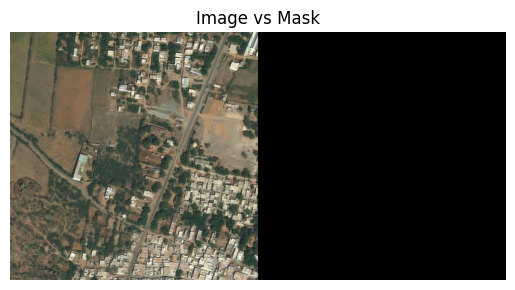

In [ ]:
mask_vis = (mask * 255).astype(np.uint8)   # scale to 0–255
mask_vis = cv2.cvtColor(mask_vis, cv2.COLOR_GRAY2BGR)  # make 3-channel

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

combined = cv2.hconcat([img_rgb, mask_vis])

plt.imshow(combined)
plt.title('Image vs Mask')
plt.axis('off')
plt.show()

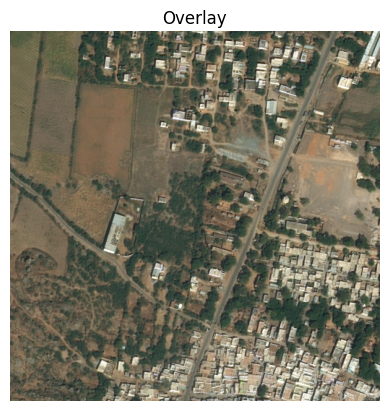

In [ ]:
overlay = img_rgb.copy()
overlay[mask == 1] = [255, 0, 0]  # highlight roads in red

plt.imshow(overlay)
plt.title('Overlay')
plt.axis('off')
plt.show()